<a href="https://colab.research.google.com/github/jessicalewinter/deep-learning-specialization/blob/main/course-notebooks/observability/Aula01_Observabilidade_comeca_nos_dados.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 1 · Observabilidade começa nos dados

**Observabilidade de Modelos e Prototipagem de Aplicações IA**

Antes de treinar qualquer modelo, precisamos entender os dados que ele vai receber. Nesta aula vamos explorar o dataset **Telco Customer Churn** (clientes de uma operadora e se cancelaram ou não o serviço) com o **plotly express**.

Você provavelmente já usa matplotlib e seaborn. A pergunta desta aula é: **o que a interatividade acrescenta quando o objetivo é diagnosticar dados?**

Roteiro:
1. Preparação
2. Um gráfico estático e uma pergunta que ele não responde
3. O mesmo gráfico, interativo
4. Zoom, filtro e legenda
5. Distribuições
6. Comparando grupos
7. Cola de referência
8. Para ir além (opcional): matriz de dispersão
9. Exercício: auditoria de dados

## 1. Preparação

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

URL_ORIGINAL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(URL_ORIGINAL)
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Cada linha é um cliente. Algumas colunas importantes:

| Coluna | Significado |
|---|---|
| `tenure` | meses como cliente |
| `MonthlyCharges` | valor da mensalidade |
| `Contract` | tipo de contrato: mensal, anual ou bienal |
| `InternetService` | tipo de internet contratada |
| `Churn` | o alvo: o cliente cancelou? |

## 2. Um gráfico estático e uma pergunta que ele não responde

Vamos começar como você provavelmente faria: um gráfico de dispersão em seaborn relacionando o tempo como cliente e a mensalidade.

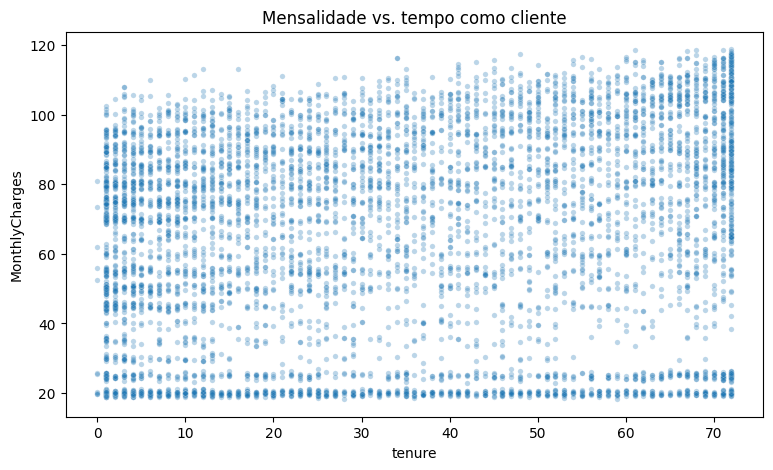

In [30]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x="tenure", y="MonthlyCharges", alpha=0.3, s=15)
plt.title("Mensalidade vs. tempo como cliente")
plt.show()

Repare na **faixa horizontal de pontos em torno de 20**. Ela atravessa todos os valores de `tenure`.

**Quem são esses clientes?** O gráfico mostra que eles existem, mas não diz quem são. Para responder, teríamos que filtrar o DataFrame por tentativa e erro, sem saber o que procurar.

## 3. O mesmo gráfico, interativo

Agora o mesmo gráfico em plotly. O parâmetro `hover_data` define o que aparece quando passamos o mouse sobre um ponto.

👉 **Passe o mouse sobre os pontos da faixa em torno de 20.** O que eles têm em comum?

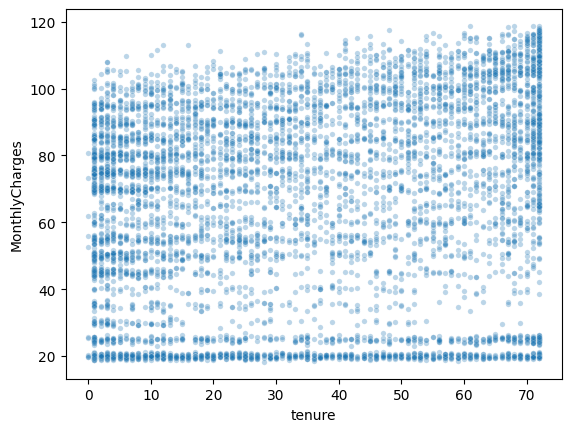

In [31]:
sns.scatterplot(data=df, x="tenure", y="MonthlyCharges", alpha=0.3, s=15)

fig = px.scatter(
    df,
    x="tenure",
    y="MonthlyCharges",
    opacity=0.4,
    color="Churn",
    hover_data=["customerID", "InternetService", "Contract", "Churn", "PaymentMethod"],
    title="Mensalidade vs. tempo como cliente (passe o mouse)",
)
fig.show()

Esse é o princípio dos **detalhes sob demanda**: o gráfico mostra o padrão geral, e o hover deixa você ir até o caso individual sem sair dele.

Depois de descobrir a resposta pelo hover, podemos confirmá-la codificando a variável na cor:

In [32]:
fig = px.scatter(
    df,
    x="tenure",
    y="MonthlyCharges",
    color="InternetService",
    opacity=0.5,
    hover_data=["customerID", "Contract", "Churn"],
    title="A faixa em torno de 20 são os clientes sem internet",
)
fig.show()

## 4. Zoom, filtro e legenda

Todo gráfico plotly já vem com estas interações:

- **Zoom:** arraste um retângulo sobre a região de interesse. Duplo clique volta à visão completa.
- **Filtro pela legenda:** um clique esconde ou mostra uma categoria; um duplo clique isola só ela.
- **Barra de ferramentas** (canto superior direito): pan, zoom, salvar como imagem.

👉 Isole os clientes que cancelaram (`Churn = Yes`) clicando duas vezes na legenda. Onde eles se concentram? Depois dê zoom na região de `tenure` baixo.

In [33]:
fig = px.scatter(
    df,
    x="tenure",
    y="MonthlyCharges",
    color="Churn",
    opacity=0.5,
    color_discrete_map=
     {
        "No": "#9AA5B1",
        "Yes": "#D1495B"
    },
    hover_data=["customerID", "Contract", "InternetService"],
    title="Quem cancela?",
)
fig.show()

> **Nota de visualização:** usamos cinza para quem não cancelou e vermelho para quem cancelou. A cor destaca o evento que nos interessa em vez de dar o mesmo peso às duas categorias.

## 5. Distribuições

Histogramas e boxplots também são interativos: o hover mostra contagens, quartis e os valores exatos dos outliers.

O parâmetro `facet_col` cria um gráfico por categoria (*small multiples*), com eixos compartilhados para facilitar a comparação.

In [34]:
fig = px.histogram(
    df, x="tenure", color="Churn", facet_col="Contract",
    color_discrete_map={"No": "#9AA5B1", "Yes": "#D1495B"},
    category_orders={"Contract": ["Month-to-month", "One year", "Two year"]},
    title="Tempo como cliente, por tipo de contrato",
)
fig.show()

In [35]:
fig = px.box(
    df, x="Contract", y="MonthlyCharges", color="Churn",
    color_discrete_map={"No": "#9AA5B1", "Yes": "#D1495B"},
    category_orders={"Contract": ["Month-to-month", "One year", "Two year"]},
    points="outliers", hover_data=["customerID"],
    title="Mensalidade por tipo de contrato",
)
fig.show()

## 6. Comparando grupos

Uma pergunta frequente: a taxa de cancelamento muda entre grupos? Ao comparar taxas, **sempre olhe também o tamanho de cada grupo**. Uma taxa calculada sobre poucos clientes é pouco confiável. Aqui o tamanho do grupo aparece no hover e no texto das barras.

In [36]:
taxa = (df.assign(cancelou=df["Churn"].eq("Yes"))
          .groupby("PaymentMethod")
          .agg(clientes=("customerID", "count"), taxa_churn=("cancelou", "mean"))
          .reset_index()
          .sort_values("taxa_churn", ascending=False))

fig = px.bar(
    taxa, x="taxa_churn", y="PaymentMethod", orientation="h",
    hover_data=["clientes"], text="clientes",
    labels={"taxa_churn": "taxa de churn", "PaymentMethod": ""},
    title="Taxa de churn por forma de pagamento (texto = nº de clientes)",
)
fig.update_xaxes(tickformat=".0%")
fig.show()

> **Nota de visualização:** as barras estão ordenadas pela taxa. Ordenar por importância facilita a leitura bem mais do que a ordem alfabética.

### Duas variáveis ao mesmo tempo: heatmap

E se quisermos cruzar **duas** variáveis categóricas, como o tipo de contrato e o tipo de internet? Um **heatmap** mostra uma tabela de números como uma grade de cores. Em plotly, isso é o `px.imshow`, que transforma qualquer matriz em uma imagem colorida.

Cada célula abaixo mostra a taxa de churn do grupo **e** quantos clientes ele tem.

In [37]:
grade = df.assign(cancelou=df["Churn"].eq("Yes"))
linhas, colunas = ["Month-to-month", "One year", "Two year"], ["DSL", "Fiber optic", "No"]
taxa_grade = grade.pivot_table(index="Contract", columns="InternetService", values="cancelou", aggfunc="mean").loc[linhas, colunas]
n_grade = grade.pivot_table(index="Contract", columns="InternetService", values="cancelou", aggfunc="count").loc[linhas, colunas]

fig = px.imshow(
    taxa_grade, color_continuous_scale="Reds", zmin=0, zmax=0.6,
    labels={"x": "tipo de internet", "y": "contrato", "color": "taxa de churn"},
    title="Taxa de churn por contrato e tipo de internet",
)
texto = [[f"{t:.0%}<br>n = {n}" for t, n in zip(lt, ln)] for lt, ln in zip(taxa_grade.values, n_grade.values)]
fig.update_traces(text=texto, texttemplate="%{text}")
fig.show()

👉 Qual combinação concentra os cancelamentos? Algum grupo tem uma taxa alta, mas poucos clientes?

> **Nota de visualização:** uma taxa vai de 0 para cima, então usamos uma escala de cor **sequencial** (do claro ao escuro). Quando os valores podem ser positivos ou negativos, como as contribuições que veremos nas aulas de explicabilidade, usamos uma escala **divergente**.

O `px.imshow` vai voltar várias vezes: na aula 2, para mostrar imagens e a **matriz de confusão** de um modelo, que é exatamente um heatmap de "classe real × classe prevista".

## 7. Cola de referência

| Pergunta | Função |
|---|---|
| Como os valores se distribuem? | `px.histogram`, `px.box` |
| Como as categorias se comparam? | `px.bar` |
| Como duas variáveis se relacionam? | `px.scatter` |
| Como algo evolui no tempo? | `px.line` |
| Como duas variáveis categóricas se combinam? | `px.imshow` sobre uma tabela cruzada |

Parâmetros que vamos usar muito:

| Parâmetro | Para quê |
|---|---|
| `hover_data=[...]` | colunas extras no hover (detalhes sob demanda) |
| `color=` | codificar uma variável na cor |
| `facet_col=`, `facet_row=` | um gráfico por categoria (small multiples) |
| `opacity=` | lidar com pontos sobrepostos |
| `category_orders={...}` | controlar a ordem das categorias |
| `color_discrete_map={...}` | escolher as cores de cada categoria |
| `log_x=True`, `log_y=True` | escala logarítmica |
| `barmode="overlay"`, `histnorm="percent"` | sobrepor e normalizar histogramas |

## Para ir além (opcional): matriz de dispersão

Uma **matriz de dispersão** mostra todos os pares de variáveis numéricas de uma vez. Em plotly, os painéis são **ligados**: selecione pontos em um painel e eles ficam destacados em todos os outros.

Antes, uma observação: a coluna `TotalCharges` foi lida como **texto**, não como número, e precisa ser convertida. Por que isso aconteceu? Guarde a pergunta para o exercício.

In [47]:
num = df.assign(TotalCharges=pd.to_numeric(df["TotalCharges"], errors="coerce"))

fig = px.scatter_matrix(
    num, dimensions=["tenure", "MonthlyCharges", "TotalCharges"], color="Churn",
    color_discrete_map={"No": "#9AA5B1", "Yes": "#D1495B"},
    hover_data=["customerID", "Contract"], opacity=0.4, height=650,
    title="Matriz de dispersão das variáveis numéricas",
)
fig.update_traces(diagonal_visible=True, showupperhalf=True, marker=dict(size=4))
fig.show()

fig.update_traces(diagonal_visible=False, showupperhalf=False, marker=dict(size=4))
fig.show()

👉 Na barra de ferramentas do gráfico, escolha **Box Select** (seleção retangular) e selecione os pontos com `tenure` alto e `MonthlyCharges` baixo em um painel. Veja onde esses mesmos clientes aparecem nos outros painéis. Duplo clique limpa a seleção.

Essa técnica é útil para encontrar valores que fogem do padrão em várias variáveis ao mesmo tempo. Ela volta na aula 3, para comparar configurações de hiperparâmetros.

---
# 9. Exercício: auditoria de dados

**Contexto.** Você recebeu os dados de churn de uma operadora para treinar um modelo de previsão de cancelamento. Antes de treinar, faça uma **auditoria**: encontre problemas nos dados que possam comprometer o modelo.

⚠️ Este arquivo **não é** o mesmo dataset usado acima. É uma versão recebida "da empresa", e pode ter problemas que o original não tem.

**Entregável (individual):** de 3 a 5 achados. Um achado pode ser um **erro nos dados** ou uma **característica que exige cuidado** no treinamento. Para cada achado:
1. **O problema**, em uma frase.
2. **A evidência:** um gráfico plotly que mostra o problema ou, quando o problema não tiver forma visual, a verificação no código que o demonstra.
3. **Os clientes afetados:** quando o problema atinge clientes específicos, cite pelo menos um (`customerID`), encontrado pela interação com o gráfico ou pelo código.
4. **A recomendação:** o que fazer antes de treinar o modelo.

**Checklist de auditoria.** Siga as seis verificações abaixo, nesta ordem. Elas são um procedimento que serve para qualquer dataset, inclusive o do seu projeto. Nem toda verificação revela um problema, e algumas revelam mais de um.

| # | Verificação | Como fazer |
|---|---|---|
| 1 | **Tipos:** cada coluna foi lida com o tipo esperado? | `dados.dtypes`; compare com o que cada coluna deveria ser (número, texto, categoria) |
| 2 | **Faltantes:** há valores vazios ou "disfarçados"? | `dados.isna().sum()`; depois procure espaços em branco e zeros onde zero não faz sentido |
| 3 | **Valores possíveis:** os números estão em faixas plausíveis? | `px.histogram` e `px.box` de cada coluna numérica; um eixo que vai muito além dos dados é um sinal. Use o hover para identificar os clientes |
| 4 | **Duplicatas:** algum cliente aparece mais de uma vez? | `dados.duplicated().sum()` e `dados["customerID"].duplicated().sum()` |
| 5 | **Alvo:** como `Churn` se distribui? | `px.histogram(dados, x="Churn", histnorm="percent")` |
| 6 | **Grupos:** algum grupo tem poucos exemplos? | contagem por categoria (`dados[coluna].value_counts()`) e taxa de churn por grupo, com o tamanho do grupo, como na seção 6 |



In [39]:
# Dados do exercício (versão "recebida da empresa")
URL_AUDITORIA = "https://drive.google.com/uc?export=download&id=1QuPWUaen0O79gecitE0GcWmIV-1_71jk"
dados = pd.read_csv(URL_AUDITORIA)
print(dados.shape)
dados.head()

(6066, 22)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,RetentionCalls
0,1053-MXTTK,Female,0,Yes,Yes,72,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),108.65,7726.35,No,0
1,3365-SAIGS,Female,0,No,No,17,Yes,No,Fiber optic,No,...,No,Yes,No,Month-to-month,Yes,Electronic check,83.55,1329.15,No,0
2,1241-EZFMJ,Male,0,Yes,No,61,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),25.45,1538.6,No,0
3,4727-MCYZG,Male,0,No,No,1,Yes,No,DSL,No,...,No,No,Yes,Month-to-month,No,Mailed check,55.55,55.55,No,0
4,1043-YCUTE,Male,0,Yes,No,56,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,Two year,Yes,Credit card (automatic),25.15,1327.15,Yes,1


### Dicas (abra só se precisar)

<details>
<summary><b>Dica 1: onde olhar</b></summary>

- **Tipos:** existe uma coluna de valores em dinheiro que não foi lida como número.
- **Faltantes:** pense em valores acumulados ao longo do tempo. Um cliente com muitos meses de casa pode ter pago zero no total?
- **Valores possíveis:** compare os histogramas das duas colunas de valores em dinheiro. Alguma tem o eixo esticado?
- **Valores possíveis (2):** olhe o valor máximo de `tenure` e quantos clientes estão exatamente nele.
- **Grupos:** entre as colunas demográficas, alguma categoria tem muito menos clientes do que seria plausível numa operadora?
</details>

<details>
<summary><b>Dica 2: mais específica</b></summary>

- **`TotalCharges`:** veja quais valores impedem a conversão: `dados.loc[pd.to_numeric(dados["TotalCharges"], errors="coerce").isna(), ["customerID", "tenure", "TotalCharges"]]`.
- **Zeros:** depois de converter `TotalCharges`, faça um `px.scatter` de `tenure` × `TotalCharges` e procure pontos colados no eixo.
- **`MonthlyCharges`:** faça um `px.scatter` de `tenure` × `MonthlyCharges` com `log_y=True` e use o hover nos pontos isolados.
- **Duplicatas:** filtre com `dados[dados.duplicated(keep=False)]` para ver as linhas repetidas lado a lado.
- **Grupos:** confira `dados["SeniorCitizen"].value_counts()` e calcule a taxa de churn de cada grupo, com o tamanho.
</details>


In [40]:
# Comece sua exploração aqui

### Achado 1

- **Problema:**
- **Evidência:** (gráfico ou verificação na célula abaixo)
- **Cliente(s) afetado(s):**
- **Recomendação:**

In [41]:
# Evidência do achado 1

### Achado 2

- **Problema:**
- **Evidência:** (gráfico ou verificação na célula abaixo)
- **Cliente(s) afetado(s):**
- **Recomendação:**

In [42]:
# Evidência do achado 2

### Achado 3

- **Problema:**
- **Evidência:** (gráfico ou verificação na célula abaixo)
- **Cliente(s) afetado(s):**
- **Recomendação:**

In [43]:
# Evidência do achado 3

### Achados 4 e 5 (opcionais)

Duplique as células acima se encontrar mais problemas.